<a href="https://colab.research.google.com/github/Anseekaa/Anseekaa/blob/main/MULTILINGUALNLP_BiLSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [62]:
!pip install -q transformers datasets sentence-transformers \
    accelerate evaluate scikit-learn pandas numpy matplotlib seaborn

In [63]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

print("Libraries imported successfully!")

Libraries imported successfully!


In [65]:
dataset = load_dataset("facebook/xnli", "en")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 392702
    })
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 5010
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 2490
    })
})


In [66]:
print(dataset["train"].column_names)

['premise', 'hypothesis', 'label']


In [67]:
print(dataset["train"].features)

{'premise': Value('string'), 'hypothesis': Value('string'), 'label': ClassLabel(names=['entailment', 'neutral', 'contradiction'])}


In [68]:
example = dataset["train"][0]
print("Premise:", example["premise"])
print("Hypothesis:", example["hypothesis"])
print("Label:", example["label"])

Premise: Conceptually cream skimming has two basic dimensions - product and geography .
Hypothesis: Product and geography are what make cream skimming work .
Label: 1


In [69]:
print(dataset["train"].column_names)

['premise', 'hypothesis', 'label']


In [70]:
print(dataset["train"].features["label"].names)

['entailment', 'neutral', 'contradiction']


In [71]:
for i in range(5):
  example = dataset["train"][i]
  print(f"\n--- Example {i+1} ---")
  print("Premise:", example["premise"])
  print("Hypothesis:", example["hypothesis"])
  print("Label:", example["label"])
  print("Label name:", dataset["train"].features["label"].names[example["label"]])


--- Example 1 ---
Premise: Conceptually cream skimming has two basic dimensions - product and geography .
Hypothesis: Product and geography are what make cream skimming work .
Label: 1
Label name: neutral

--- Example 2 ---
Premise: you know during the season and i guess at at your level uh you lose them to the next level if if they decide to recall the the parent team the Braves decide to call to recall a guy from triple A then a double A guy goes up to replace him and a single A guy goes up to replace him
Hypothesis: You lose the things to the following level if the people recall .
Label: 0
Label name: entailment

--- Example 3 ---
Premise: One of our number will carry out your instructions minutely .
Hypothesis: A member of my team will execute your orders with immense precision .
Label: 0
Label name: entailment

--- Example 4 ---
Premise: How do you know ? All this is their information again .
Hypothesis: This information belongs to them .
Label: 0
Label name: entailment

--- Exam

In [72]:
print("Training:", len(dataset["train"]))
print("Validation:", len(dataset["validation"]))
print("Test:", len(dataset["test"]))

Training: 392702
Validation: 2490
Test: 5010


In [73]:
from collections import Counter
labels = dataset["train"]["label"]
print(Counter(labels))

Counter({2: 130903, 1: 130900, 0: 130899})


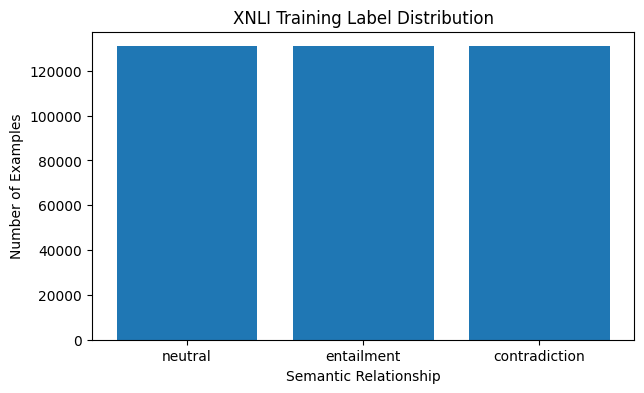

In [74]:
label_names = dataset["train"].features["label"].names
label_counts = Counter(labels)
plt.figure(figsize = (7,4))
plt.bar(
    [label_names[i] for i in label_counts.keys()],
    label_counts.values()
)

plt.title("XNLI Training Label Distribution")
plt.xlabel("Semantic Relationship")
plt.ylabel("Number of Examples")

plt.show()

In [75]:
hindi_dataset = load_dataset("facebook/xnli", "hi")
print(hindi_dataset)

DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 392702
    })
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 5010
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 2490
    })
})


In [76]:
english_dataset = dataset

In [77]:
print(hindi_dataset["train"].column_names)

['premise', 'hypothesis', 'label']


In [78]:
print(hindi_dataset["train"].features["label"].names)

['entailment', 'neutral', 'contradiction']


In [79]:
for i in range(5):
  example = hindi_dataset["train"][i]

  print(f"\n--- Hindi Example {i+1} ---")
  print("Premise:", example["premise"])
  print("Hypothesis:", example["hypothesis"])
  print("Label:", example["label"])
  print(
      "Label name:",
      hindi_dataset["train"].features["label"].names[example["label"]]
  )


--- Hindi Example 1 ---
Premise: Conceptually क ् रीम एंजलिस में दो मूल आयाम हैं - उत ् पाद और भूगोल ।
Hypothesis: उत ् पाद और भूगोल क ् या क ् रीम एंजलिस काम बनाते हैं .
Label: 1
Label name: neutral

--- Hindi Example 2 ---
Premise: आप मौसम के दौरान जानते हैं और मैं अपने स ् तर पर लगता है कि आप उन ् हें अगले स ् तर पर खो देते हैं यदि वे माता-पिता को याद करने का निर ् णय करते हैं तो braves को एक आदमी को याद करने का निर ् णय लेने का निर ् णय करता है तो एक डबल आदमी के लिए चला जाता है उसे बदलें और एक अकेला आदमी उसे बदलने के लिए चला जाता है
Hypothesis: अगर लोग याद करते हैं तो आप निम ् न स ् तर पर चीज ़ ें खो देते हैं .
Label: 0
Label name: entailment

--- Hindi Example 3 ---
Premise: हमारे एक नंबर में से एक आपके निर ् देशों को मिनटों में ले जाएगा .
Hypothesis: मेरी टीम का एक सदस ् य आपके आदेश को बड ़ ी सूक ् ष ् मता से निष ् पादित करेगा .
Label: 0
Label name: entailment

--- Hindi Example 4 ---
Premise: आप कैसे जानते हैं ? ये सब उनकी जानकारी फिर से है ।
Hypothesis: यह जानकारी उनके लिए है 

In [80]:
print("English example:")
print("Premise:", english_dataset["train"][0]["premise"])
print("Hypothesis:", english_dataset["train"][0]["hypothesis"])
print("Label:", english_dataset["train"][0]["label"])
print("\nHindi example:")
print("Premise:", hindi_dataset["train"][0]["premise"])
print("Hypothesis:", hindi_dataset["train"][0]["hypothesis"])
print("Label:", hindi_dataset["train"][0]["label"])

English example:
Premise: Conceptually cream skimming has two basic dimensions - product and geography .
Hypothesis: Product and geography are what make cream skimming work .
Label: 1

Hindi example:
Premise: Conceptually क ् रीम एंजलिस में दो मूल आयाम हैं - उत ् पाद और भूगोल ।
Hypothesis: उत ् पाद और भूगोल क ् या क ् रीम एंजलिस काम बनाते हैं .
Label: 1


In [81]:
print(
    "English label:",
    english_dataset["train"][0]["label"]
)
print(
    "Hindi label:",
    hindi_dataset["train"][0]["label"]
)

English label: 1
Hindi label: 1


In [82]:
for i in range(10):

    english_label = english_dataset["train"][i]["label"]
    hindi_label = hindi_dataset["train"][i]["label"]

    print(
        f"Example {i+1}: "
        f"English = {english_label}, "
        f"Hindi = {hindi_label}, "
        f"Match = {english_label == hindi_label}"
    )

Example 1: English = 1, Hindi = 1, Match = True
Example 2: English = 0, Hindi = 0, Match = True
Example 3: English = 0, Hindi = 0, Match = True
Example 4: English = 0, Hindi = 0, Match = True
Example 5: English = 1, Hindi = 1, Match = True
Example 6: English = 0, Hindi = 0, Match = True
Example 7: English = 1, Hindi = 1, Match = True
Example 8: English = 0, Hindi = 0, Match = True
Example 9: English = 2, Hindi = 2, Match = True
Example 10: English = 2, Hindi = 2, Match = True


In [83]:
matches = 0
total = 1000

for i in range(total):

    english_label = english_dataset["train"][i]["label"]
    hindi_label = hindi_dataset["train"][i]["label"]

    if english_label == hindi_label:
        matches += 1

print("Matching labels:", matches)
print("Total checked:", total)
print("Match percentage:", matches / total * 100)

Matching labels: 1000
Total checked: 1000
Match percentage: 100.0


In [84]:
import pandas as pd
num_examples = 1000
cross_lingual_data = []
for i in range(num_examples):
  english = english_dataset["train"][i]
  hindi = hindi_dataset["train"][i]
  cross_lingual_data.append({
      "premise": english["premise"],
      "hypothesis": hindi["hypothesis"],
      "premise_language": "English",
      "hypothesis_language": "Hindi",
      "label": english["label"]
  })
  cross_lingual_data.append({
      "premise": hindi["premise"],
      "hypothesis": english["hypothesis"],
      "premise_language": "Hindi",
      "hypothesis_language": "English",
      "label": english["label"]
  })
cross_lingual_df = pd.DataFrame(cross_lingual_data)
print("Dataset shape:", cross_lingual_df.shape)
print("\nFirst 5 examples:")
display(cross_lingual_df.head())

Dataset shape: (2000, 5)

First 5 examples:


,premise,hypothesis,premise_language,hypothesis_language,label
0,Conceptually cream skimming has two basic dime...,उत ् पाद और भूगोल क ् या क ् रीम एंजलिस काम बन...,English,Hindi,1
1,Conceptually क ् रीम एंजलिस में दो मूल आयाम है...,Product and geography are what make cream skim...,Hindi,English,1
2,you know during the season and i guess at at y...,अगर लोग याद करते हैं तो आप निम ् न स ् तर पर च...,English,Hindi,0
3,आप मौसम के दौरान जानते हैं और मैं अपने स ् तर ...,You lose the things to the following level if ...,Hindi,English,0
4,One of our number will carry out your instruct...,मेरी टीम का एक सदस ् य आपके आदेश को बड ़ ी सूक...,English,Hindi,0


In [85]:
print(cross_lingual_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   premise              2000 non-null   object
 1   hypothesis           2000 non-null   object
 2   premise_language     2000 non-null   object
 3   hypothesis_language  2000 non-null   object
 4   label                2000 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 78.3+ KB
None


In [86]:
print(cross_lingual_df["label"].value_counts())

label
2    750
0    686
1    564
Name: count, dtype: int64


In [87]:
print(
    cross_lingual_df[
        ["premise_language", "hypothesis_language"]
    ].value_counts()
)

premise_language  hypothesis_language
English           Hindi                  1000
Hindi             English                1000
Name: count, dtype: int64


In [88]:
cross_lingual_df.to_csv(
    "polysem_crosslingual_v1.csv",
    index = False

)
print("Saved Successfully!")

Saved Successfully!


In [89]:
print(cross_lingual_df.shape)
display(cross_lingual_df.head())
print(cross_lingual_df["label"].value_counts())
print(cross_lingual_df[
    ["premise_language", "hypothesis_language"]
].value_counts())

(2000, 5)


,premise,hypothesis,premise_language,hypothesis_language,label
0,Conceptually cream skimming has two basic dime...,उत ् पाद और भूगोल क ् या क ् रीम एंजलिस काम बन...,English,Hindi,1
1,Conceptually क ् रीम एंजलिस में दो मूल आयाम है...,Product and geography are what make cream skim...,Hindi,English,1
2,you know during the season and i guess at at y...,अगर लोग याद करते हैं तो आप निम ् न स ् तर पर च...,English,Hindi,0
3,आप मौसम के दौरान जानते हैं और मैं अपने स ् तर ...,You lose the things to the following level if ...,Hindi,English,0
4,One of our number will carry out your instruct...,मेरी टीम का एक सदस ् य आपके आदेश को बड ़ ी सूक...,English,Hindi,0


label
2    750
0    686
1    564
Name: count, dtype: int64
premise_language  hypothesis_language
English           Hindi                  1000
Hindi             English                1000
Name: count, dtype: int64


In [90]:
from collections import defaultdict

label_indices = defaultdict(list)

for i, label in enumerate(english_dataset["train"]["label"]):
    label_indices[label].append(i)

for label, indices in label_indices.items():
    print(
        f"Label {label} ({english_dataset['train'].features['label'].names[label]}): "
        f"{len(indices)} examples"
    )

Label 1 (neutral): 130900 examples
Label 0 (entailment): 130899 examples
Label 2 (contradiction): 130903 examples


In [91]:
import random

random.seed(42)

selected_indices = []

samples_per_class = 1000

for label in [0, 1, 2]:

    selected = random.sample(
        label_indices[label],
        samples_per_class
    )

    selected_indices.extend(selected)

random.shuffle(selected_indices)

print("Total selected:", len(selected_indices))

Total selected: 3000


In [92]:
cross_lingual_data = []

for i in selected_indices:

    english = english_dataset["train"][i]
    hindi = hindi_dataset["train"][i]

    label = english["label"]


    cross_lingual_data.append({
        "premise": english["premise"],
        "hypothesis": hindi["hypothesis"],
        "premise_language": "English",
        "hypothesis_language": "Hindi",
        "label": label
    })


    cross_lingual_data.append({
        "premise": hindi["premise"],
        "hypothesis": english["hypothesis"],
        "premise_language": "Hindi",
        "hypothesis_language": "English",
        "label": label
    })

cross_lingual_df = pd.DataFrame(cross_lingual_data)

print("Dataset shape:", cross_lingual_df.shape)

Dataset shape: (6000, 5)


In [93]:
print(
    cross_lingual_df["label"]
    .value_counts()
    .sort_index()
)

label
0    2000
1    2000
2    2000
Name: count, dtype: int64


In [94]:
print(
    cross_lingual_df[
        ["premise_language", "hypothesis_language"]
    ].value_counts()
)

premise_language  hypothesis_language
English           Hindi                  3000
Hindi             English                3000
Name: count, dtype: int64


In [95]:
cross_lingual_data = []

for i in selected_indices:

    english = english_dataset["train"][i]
    hindi = hindi_dataset["train"][i]

    label = english["label"]

    cross_lingual_data.append({
        "original_id": i,
        "premise": english["premise"],
        "hypothesis": hindi["hypothesis"],
        "premise_language": "English",
        "hypothesis_language": "Hindi",
        "label": label
    })


    cross_lingual_data.append({
        "original_id": i,
        "premise": hindi["premise"],
        "hypothesis": english["hypothesis"],
        "premise_language": "Hindi",
        "hypothesis_language": "English",
        "label": label
    })

cross_lingual_df = pd.DataFrame(cross_lingual_data)

print("Dataset shape:", cross_lingual_df.shape)
print(cross_lingual_df.head())

Dataset shape: (6000, 6)
   original_id                                            premise  \
0       329230  H-2A workers may be more attractive to employe...   
1       329230  एच-2 कर ् मचारियों को कई कारणों से नियोक ् ताओ...   
2       183712  The ferocity of their warriors and the dark ma...   
3       183712  उनके योद ् धाओं की उग ् रता और उनकी चुड ़ ैलों...   
4        98111  so i thought well i need an outdoor cat but if...   

                                          hypothesis premise_language  \
0  नियोक ् ताओं को पता है कि 2 कर ् मचारियों को क...          English   
1  Employers find H-2A workers must pass stringen...            Hindi   
2                उनके चुड ़ ैलों ने गहरा जादू किया ।          English   
3               Their witches possessed dark magic .            Hindi   
4  मैं एक पट ् टा पर बाहर अपनी इनडोर बिल ् ली ले ...          English   

  hypothesis_language  label  
0               Hindi      1  
1             English      1  
2               Hindi      0

In [96]:
from sklearn.model_selection import train_test_split

original_ids = cross_lingual_df["original_id"].unique()

train_ids, temp_ids = train_test_split(
    original_ids,
    test_size=0.30,
    random_state=42,
    stratify=[
        english_dataset["train"][int(i)]["label"]
        for i in original_ids
    ]
)

val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=42,
    stratify=[
        english_dataset["train"][int(i)]["label"]
        for i in temp_ids
    ]
)

print("Original examples:")
print("Train:", len(train_ids))
print("Validation:", len(val_ids))
print("Test:", len(test_ids))

Original examples:
Train: 2100
Validation: 450
Test: 450


In [97]:
train_df = cross_lingual_df[
    cross_lingual_df["original_id"].isin(train_ids)
].reset_index(drop=True)

val_df = cross_lingual_df[
    cross_lingual_df["original_id"].isin(val_ids)
].reset_index(drop=True)

test_df = cross_lingual_df[
    cross_lingual_df["original_id"].isin(test_ids)
].reset_index(drop=True)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (4200, 6)
Validation: (900, 6)
Test: (900, 6)


In [98]:
print(
    "Train ∩ Validation:",
    len(set(train_df["original_id"]) & set(val_df["original_id"]))
)

print(
    "Train ∩ Test:",
    len(set(train_df["original_id"]) & set(test_df["original_id"]))
)

print(
    "Validation ∩ Test:",
    len(set(val_df["original_id"]) & set(test_df["original_id"]))
)

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [99]:
print("TRAIN")
print(train_df["label"].value_counts().sort_index())

print("\nVALIDATION")
print(val_df["label"].value_counts().sort_index())

print("\nTEST")
print(test_df["label"].value_counts().sort_index())

TRAIN
label
0    1400
1    1400
2    1400
Name: count, dtype: int64

VALIDATION
label
0    300
1    300
2    300
Name: count, dtype: int64

TEST
label
0    300
1    300
2    300
Name: count, dtype: int64


In [100]:
from sklearn.feature_extraction.text import TfidfVectorizer
train_text = (
    train_df["premise"] + " [SEP] " + train_df["hypothesis"]
)

val_text = (
    val_df["premise"] + " [SEP] " + val_df["hypothesis"]
)

test_text = (
    test_df["premise"] + " [SEP] " + test_df["hypothesis"]
)

print(train_text.head())

0    The ferocity of their warriors and the dark ma...
1    उनके योद ् धाओं की उग ् रता और उनकी चुड ़ ैलों...
2    so i thought well i need an outdoor cat but if...
3    तो मैंने सोचा कि मुझे एक बाहरी बिल ् ली की जरू...
4    Gross The Three Trials of Oscar Wilde ( Minett...
dtype: object


In [101]:
tfidf = TfidfVectorizer(
    max_features = 20000,
    ngram_range=(1,2),
    min_df=2
)
X_train = tfidf.fit_transform(train_text)
X_val = tfidf.transform(val_text)
X_test = tfidf.transform(test_text)
y_train = train_df["label"]
y_val = val_df["label"]
y_test = test_df["label"]

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)





Train shape: (4200, 18997)
Validation shape: (900, 18997)
Test shape: (900, 18997)


In [102]:
from sklearn.linear_model import LogisticRegression
tfidf_model = LogisticRegression(
    max_iter = 1000,
    random_state = 42
)

tfidf_model.fit(X_train, y_train)
print("TF-IDF model trained!")

TF-IDF model trained!


In [103]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
val_predictions = tfidf_model.predict(X_val)
print("Validation Accuracy:",
      accuracy_score(y_val, val_predictions))
print("\nClassification Report:")
print(
    classification_report(
        y_val,
        val_predictions,
        target_names = [
            "Entailment",
            "Neutral",
            "Contradiction"
        ]
    )
)

Validation Accuracy: 0.39111111111111113

Classification Report:
               precision    recall  f1-score   support

   Entailment       0.36      0.32      0.34       300
      Neutral       0.37      0.42      0.39       300
Contradiction       0.44      0.44      0.44       300

     accuracy                           0.39       900
    macro avg       0.39      0.39      0.39       900
 weighted avg       0.39      0.39      0.39       900



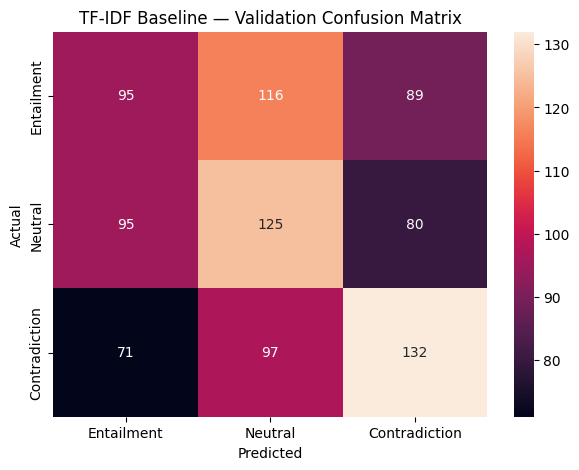

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_val, val_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Entailment",
        "Neutral",
        "Contradiction"
    ],
    yticklabels=[
        "Entailment",
        "Neutral",
        "Contradiction"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("TF-IDF Baseline — Validation Confusion Matrix")

plt.show()

In [105]:
import re
from collections import Counter
def tokenize(text):
  text = str(text).lower().strip()
  return text.split()

In [106]:
sample = train_df.iloc[0]["premise"]
print("Original:")
print(sample)
print("\nTokens:")
print(tokenize(sample))

Original:
The ferocity of their warriors and the dark magics of their witches could not stop powder and shot .

Tokens:
['the', 'ferocity', 'of', 'their', 'warriors', 'and', 'the', 'dark', 'magics', 'of', 'their', 'witches', 'could', 'not', 'stop', 'powder', 'and', 'shot', '.']


In [107]:
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
counter = Counter()
for text in train_df["premise"]:
  counter.update(tokenize(text))
for text in train_df["hypothesis"]:
  counter.update(tokenize(text))
print("Unique toekens:", len(counter))

Unique toekens: 15503


In [108]:
MAX_VOCAB_SIZE = 30000
vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for token, count in counter.most_common(MAX_VOCAB_SIZE - 2):
  vocab[token] = len(vocab)
print("Vocabulary size:", len(vocab))

Vocabulary size: 15505


In [109]:
def encode(text, max_length = 64):
  tokens = tokenize(text)

  ids = [
      vocab.get(token, vocab[UNK_TOKEN])
      for token in tokens
  ]

  ids = ids[:max_length]
  ids += [vocab[PAD_TOKEN]] * (max_length - len(ids))

  return ids


In [110]:
encoded = encode(train_df.iloc[0]["premise"])

print(encoded)
print("Length:", len(encoded))

[5, 9367, 9, 119, 9368, 11, 5, 4577, 9369, 9, 119, 5979, 221, 59, 1255, 9370, 11, 1950, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Length: 64


In [111]:
import torch
from torch.utils.data import Dataset, DataLoader

class NLIDataset(Dataset):

    def __init__(self, dataframe, max_length=64):
        self.df = dataframe.reset_index(drop=True)
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]


        premise = torch.tensor(
            encode(row["premise"], self.max_length),
            dtype=torch.long
        )

        hypothesis = torch.tensor(
            encode(row["hypothesis"], self.max_length),
            dtype=torch.long
        )

        label = torch.tensor(
            row["label"],
            dtype=torch.long
        )

        return premise, hypothesis, label

In [112]:
train_dataset = NLIDataset(train_df)
val_dataset = NLIDataset(val_df)
test_dataset = NLIDataset(test_df)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 4200
Validation: 900
Test: 900


In [113]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [114]:
# Re-instantiate the datasets using the updated NLIDataset class
train_dataset = NLIDataset(train_df)
val_dataset = NLIDataset(val_df)
test_dataset = NLIDataset(test_df)

# Recreate the DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# Fetch and print batch shapes
premise_batch, hypothesis_batch, label_batch = next(iter(train_loader))

print("Premise shape:", premise_batch.shape)
print("Hypothesis shape:", hypothesis_batch.shape)
print("Labels shape:", label_batch.shape)

Premise shape: torch.Size([32, 64])
Hypothesis shape: torch.Size([32, 64])
Labels shape: torch.Size([32])


In [115]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [123]:

from torch.nn.utils.rnn import pack_padded_sequence

class BiLSTM_NLI(nn.Module):

    def __init__(self, vocab_size, embedding_dim=100, hidden_dim=64):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.embedding_dropout = nn.Dropout(0.3)

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.5)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 3)
        )

    def encode(self, x):

        lengths = (x != 0).sum(dim=1).clamp(min=1)

        embedded = self.embedding(x)
        embedded = self.embedding_dropout(embedded)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        return torch.cat(
            (hidden[-2], hidden[-1]),
            dim=1
        )

    def forward(self, premise, hypothesis):

        p = self.encode(premise)
        h = self.encode(hypothesis)

        combined = torch.cat(
            (p, h, torch.abs(p-h), p*h),
            dim=1
        )

        return self.classifier(self.dropout(combined))


In [124]:
model = BiLSTM_NLI(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128
).to(device)

print(model)

print(
    "\nTotal parameters:",
    sum(p.numel() for p in model.parameters())
)

BiLSTM_NLI(
  (embedding): Embedding(15505, 128, padding_idx=0)
  (embedding_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (classifier): Sequential(
    (0): Linear(in_features=1024, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=128, out_features=3, bias=True)
  )
)

Total parameters: 2380419


In [125]:
premise_batch, hypothesis_batch, label_batch = next(iter(train_loader))

premise_batch = premise_batch.to(device)
hypothesis_batch = hypothesis_batch.to(device)

with torch.no_grad():
    output = model(premise_batch, hypothesis_batch)

print("Output shape:", output.shape)
print("Predictions:", output.argmax(dim=1))

Output shape: torch.Size([32, 3])
Predictions: tensor([2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 0, 2, 2, 2], device='cuda:0')


In [127]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0005,
    weight_decay = 0.01
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0005
    maximize: False
    weight_decay: 0.01
)


In [128]:
def train_one_epoch(model, loader):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for premise, hypothesis, labels in loader:

        premise = premise.to(device)
        hypothesis = hypothesis.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(premise, hypothesis)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    accuracy = correct / total
    avg_loss = total_loss / len(loader)

    return avg_loss, accuracy

In [129]:
def evaluate(model, loader):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for premise, hypothesis, labels in loader:

            premise = premise.to(device)
            hypothesis = hypothesis.to(device)
            labels = labels.to(device)

            outputs = model(premise, hypothesis)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return total_loss / len(loader), correct / total

In [130]:

import copy

EPOCHS = 15
PATIENCE = 3

best_val_loss = float("inf")
best_state = None
patience_counter = 0

history_v2 = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model, train_loader
    )

    val_loss, val_acc = evaluate(
        model, val_loader
    )

    history_v2["train_loss"].append(train_loss)
    history_v2["train_accuracy"].append(train_acc)
    history_v2["val_loss"].append(val_loss)
    history_v2["val_accuracy"].append(val_acc)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        patience_counter = 0

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered!")
        break

model.load_state_dict(best_state)

torch.save(
    model.state_dict(),
    "polysem_bilstm_v2.pth"
)

print("\nBest model restored and saved!")



Epoch 1/15
Train Loss: 1.1004
Train Accuracy: 0.3336
Validation Loss: 1.0971
Validation Accuracy: 0.3511

Epoch 2/15
Train Loss: 1.0973
Train Accuracy: 0.3505
Validation Loss: 1.0969
Validation Accuracy: 0.3511

Epoch 3/15
Train Loss: 1.0965
Train Accuracy: 0.3702
Validation Loss: 1.0966
Validation Accuracy: 0.3633

Epoch 4/15
Train Loss: 1.0970
Train Accuracy: 0.3550
Validation Loss: 1.0969
Validation Accuracy: 0.3756

Epoch 5/15
Train Loss: 1.0974
Train Accuracy: 0.3507
Validation Loss: 1.0974
Validation Accuracy: 0.3444

Epoch 6/15
Train Loss: 1.0975
Train Accuracy: 0.3605
Validation Loss: 1.0974
Validation Accuracy: 0.3744

Early stopping triggered!

Best model restored and saved!
